# Result figures

This notebook draws the result figures used in the README and in `docs/results.md`. It reads only the
aggregate result files in `results/main_v04/` (described in `results/README.md`) and writes PNG files to
`docs/figures/`. It needs no GPU, no model weights and no data, only `numpy` and `matplotlib`.

Run it from the repository root or from the `notebooks/` folder. Systems are named by what they are:

| Name in the figures | System |
|---|---|
| Ours | VoxTurn fine-tuned with LoRA, with the final read-out (step 2d) over its last-layer states and its per-second audio-encoder outputs |
| Same model, original read-out | The same fine-tuned model with the output head it was trained with |
| Fine-tuned Whisper encoder + features | Whisper-base encoder fully fine-tuned on the 8 s window, plus the situation features (detector scores, transcripts, speaker tags, history) |
| Late fusion of frozen audio and text features | Frozen audio features (detector embedding, off-the-shelf VoxTurn answers) and text embeddings, joined in a small classifier |
| Label reader trained on our data (no audio) | The same small classifier on detector scores, transcripts and history, without audio |
| Text only | The same classifier without any sound information |
| Tuned rule system | Hand-written rules with thresholds tuned on the development set |
| Local LLM reader (Qwen3.5-4B, 4-bit) | A local LLM that reads the situation text |
| Gemini reader, fast model / strong model | Gemini models that read the situation text (48 examples in the prompt) |
| Gemini listening to the audio | Gemini given the audio itself |
| Off-the-shelf VoxTurn | VoxTurn without fine-tuning |
| Reference: Gemini reader given perfect labels | Not a rival: the strong Gemini reader given correct event labels |

The five test parts are "respond, hearing", "respond, reaction", "stop, reaction", "stop, movement" and
"episodes". Intervals are 95% cluster-bootstrap intervals (clustered by conversation, event recording and a
second key recording).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Rectangle

# The repository root is the working directory or its parent (when run from notebooks/).
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "results" / "main_v04").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("results/main_v04 not found: run this notebook from the repository root or notebooks/")
RES = ROOT / "results" / "main_v04"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


def load(name):
    with open(RES / name, encoding="utf-8") as f:
        return json.load(f)


decision = load("decision_test_final.json")       # main comparison, test set
grounding = load("grounding_v06_test.json")       # matched grounding test and natural error analysis, test set
grounding_dev = load("grounding_v06_dev.json")    # the same report on the development set (read-out iterations)
noise = load("noise_test.json")                   # extra background noise, test set
mirror = load("mirror_vs_ears_replication.json")  # masked-sound check, replication split
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | matplotlib 3.11.2


## Names, colours and drawing helpers

Colours follow one rule per job: our system is the single highlighted series (blue) and every other system
is grey; the read-out iterations use three categorical colours; noise levels use one ordered blue ramp.
Gridlines and axes are thin and light so that the data carries the ink.

In [2]:
NAMES = {
    "ours": "Ours",
    "L1": "Same model, original read-out",
    "L3": "Fine-tuned Whisper encoder + features",
    "L2": "Late fusion of frozen audio and text features",
    "T": "Label reader trained on our data (no audio)",
    "T0": "Text only",
    "B1-strong": "Tuned rule system",
    "B2-local": "Local LLM reader (Qwen3.5-4B, 4-bit)",
    "B2-fast": "Gemini reader, fast model",
    "B2-strong": "Gemini reader, strong model",
    "B3": "Gemini listening to the audio",
    "VoxTurn alone": "Off-the-shelf VoxTurn",
    "B2-ideal": "Reference: Gemini reader given perfect labels",
}
REFERENCE = "B2-ideal"
PARTS = {"r_hear": "Respond, hearing", "r_react": "Respond, reaction", "s_react": "Stop, reaction",
         "s_move": "Stop, movement", "episode": "Episodes"}

SURFACE = "#fcfcfb"   # chart surface
INK = "#0b0b0b"       # primary text
INK2 = "#52514e"      # secondary text
MUTED = "#898781"     # thin marks of the other systems, reference lines
GRID = "#e1e0d9"      # gridlines
AXIS = "#c3c2b7"      # baselines, and the fill of the other systems' bars
OURS = "#2a78d6"      # the highlighted system
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]                          # categorical slots 1-3
LEVELS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # ordered ramp: clean to +40 dB
MINUS = "−"
DPI = 200
ROW = 0.3            # inches per system row
DOT = dict(ms=8, mec=SURFACE, mew=1.5)   # a filled dot with a 2 px ring in the surface colour

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.75, "axes.labelcolor": INK2, "axes.labelsize": 9,
    "axes.titlesize": 9.5, "axes.titleweight": "semibold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.titlepad": 8, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8.5, "ytick.labelsize": 9,
    "xtick.major.size": 0, "ytick.major.size": 0, "xtick.major.pad": 5, "ytick.major.pad": 8,
    "grid.color": GRID, "grid.linewidth": 0.75, "grid.linestyle": "-",
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.solid_capstyle": "round",
})


def signed(x, nd=1):
    """+5.6 / −2.0 with a true minus sign."""
    return f"{x:+.{nd}f}".replace("-", MINUS)


def fixed(x, nd=3):
    return f"{x:.{nd}f}".replace("-", MINUS)


def axes_in(fig, left, bottom, width, height, **kw):
    """Axes placed in inches from the figure's bottom-left corner (a fixed layout keeps the bar ends exact)."""
    W, H = fig.get_figwidth(), fig.get_figheight()
    return fig.add_axes([left / W, bottom / H, width / W, height / H], **kw)


def heading(fig, title, subtitle, left=0.25, top=0.2):
    W, H = fig.get_figwidth(), fig.get_figheight()
    fig.text(left / W, 1 - top / H, title, fontsize=12.5, fontweight="semibold", color=INK, va="top")
    fig.text(left / W, 1 - (top + 0.33) / H, subtitle, fontsize=9, color=INK2, va="top", linespacing=1.45)


def footnote(fig, text, left=0.25, bottom=0.12):
    W, H = fig.get_figwidth(), fig.get_figheight()
    fig.text(left / W, bottom / H, text, fontsize=8, color=INK2, va="bottom", linespacing=1.45)


def rows_axis(ax, ys, ticks, labels, baseline=True):
    """Value axis along x for one row per system: gridlines (and the zero baseline) span the rows only."""
    top, bottom = min(ys) - 0.5, max(ys) + 0.5
    ax.set_xticks(ticks, labels)
    ax.vlines(ticks, top, bottom, color=GRID, lw=0.75, zorder=0)
    if baseline:
        ax.plot([0, 0], [top, bottom], color=AXIS, lw=0.75, zorder=1.5)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(False)


def name_labels(ax, keys, ys):
    ax.set_yticks(ys)
    ax.set_yticklabels([NAMES[k] for k in keys])
    for k, t in zip(keys, ax.get_yticklabels()):
        t.set_color(INK if k == "ours" else INK2)
        t.set_fontweight("semibold" if k == "ours" else "normal")
        t.set_fontstyle("italic" if k == REFERENCE else "normal")


def hbar(ax, y, value, height, color, radius_pt=3.0):
    """Horizontal bar from 0 to value: square at the baseline, 4 px rounded corners at the data end.
    Call after the axes limits are set; the axes must not move afterwards."""
    if value <= 0:
        return
    fig, pos = ax.figure, ax.get_position()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    rx = radius_pt / 72 * abs(x1 - x0) / (fig.get_figwidth() * pos.width)
    ry = min(radius_pt / 72 * abs(y1 - y0) / (fig.get_figheight() * pos.height), height / 2)
    if value <= rx:
        ax.add_patch(Rectangle((0, y - height / 2), value, height, color=color, lw=0, zorder=2))
        return
    ax.add_patch(FancyBboxPatch((0, y - height / 2), value, height, boxstyle=f"round,pad=0,rounding_size={rx}",
                                mutation_aspect=ry / rx, color=color, lw=0, zorder=2))
    ax.add_patch(Rectangle((0, y - height / 2), value - rx, height, color=color, lw=0, zorder=2))


def tip_label(ax, x, y, text, ours=False, **kw):
    """Value label beside a mark; its surface-coloured box interrupts gridlines and reference lines."""
    ax.text(x, y, text, va="center", fontsize=8.5, color=INK if ours else INK2,
            fontweight="semibold" if ours else "normal", zorder=5,
            bbox=dict(boxstyle="square,pad=0.12", fc=SURFACE, ec="none"), **kw)


def save(fig, name):
    path = FIG / name
    fig.savefig(path, dpi=DPI, bbox_inches="tight", pad_inches=0.12)
    print("saved", path.relative_to(ROOT).as_posix())

## (a) Main comparison on the test set

Left: the mean of the five part accuracies for every system, ours highlighted. The vertical line is the
reference that is given perfect event labels. Right: ours minus each system in points, with 95% intervals.
For the five rivals (rule system, local LLM and the three Gemini systems) these are the comparisons fixed in
advance (`per_rival`); for our own baselines they come from `comparisons`. The Gemini systems returned text
answers only, so their answer loss, measured on the development set, is subtracted from ours' lead (the
unadjusted values are also in the file).

saved docs/figures/main_comparison_test.png


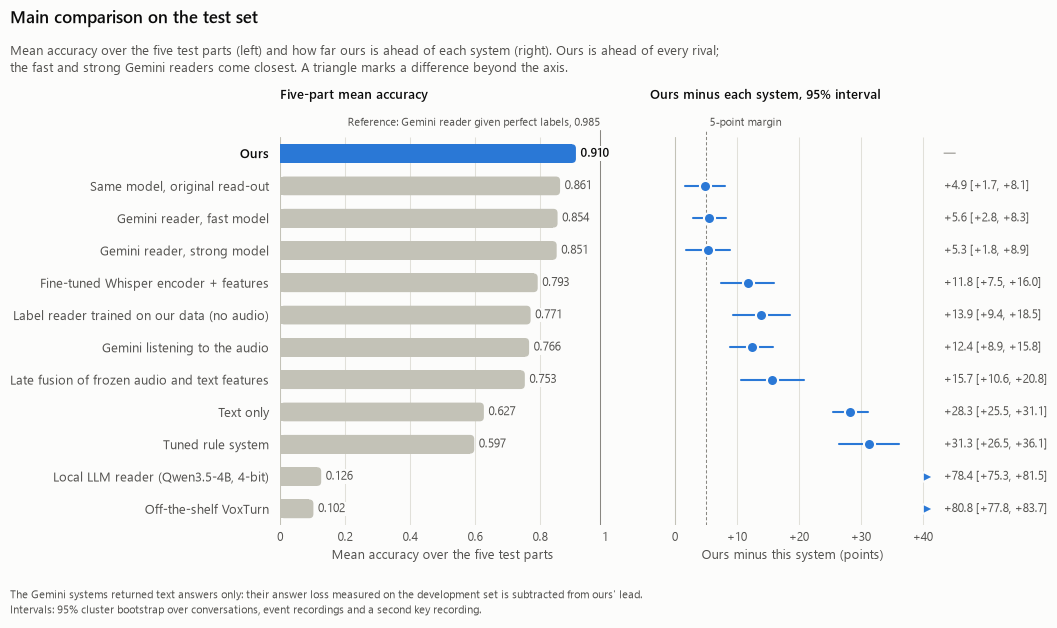

Five-part mean, test set:
  Ours                                             0.910
  Same model, original read-out                    0.861
  Gemini reader, fast model                        0.854
  Gemini reader, strong model                      0.851
  Fine-tuned Whisper encoder + features            0.793
  Label reader trained on our data (no audio)      0.771
  Gemini listening to the audio                    0.766
  Late fusion of frozen audio and text features    0.753
  Text only                                        0.627
  Tuned rule system                                0.597
  Local LLM reader (Qwen3.5-4B, 4-bit)             0.126
  Off-the-shelf VoxTurn                            0.102
  Reference: Gemini reader given perfect labels    0.985
Not plotted (simple references): T0-single 0.529, No environment 0.109, Copy previous 0.067


In [3]:
S = decision["systems"]
ORDER = sorted([k for k in NAMES if k in S and k != REFERENCE], key=lambda k: -S[k]["primary"])


def ours_minus(k):
    """Ours minus system k on the five-part mean, in points: (point, lower, upper)."""
    if k in decision["per_rival"]:
        r = decision["per_rival"][k]
        p, (lo, hi) = r["diff"], r["ci95"]
    else:
        c = decision["comparisons"][k]["primary"]
        p, (lo, hi) = c["point"], c["ci95"]
    return 100 * p, 100 * lo, 100 * hi


for k in decision["per_rival"]:   # the two sources agree for the rivals
    assert abs(decision["comparisons"][k]["primary"]["point"] - decision["per_rival"][k]["diff"]) < 1e-9

n = len(ORDER)
ys = np.arange(n)
plot_h, bottom = n * ROW + 0.55, 1.05
fig = plt.figure(figsize=(11.2, 1.2 + plot_h + bottom))
ylim = (n - 0.5, -1.35)

ax = axes_in(fig, 2.95, bottom, 3.25, plot_h)
ax.set_xlim(0, 1.0)
ax.set_ylim(*ylim)
rows_axis(ax, ys, [0, 0.2, 0.4, 0.6, 0.8, 1.0], ["0", "0.2", "0.4", "0.6", "0.8", "1"])
name_labels(ax, ORDER, ys)
ref = S[REFERENCE]["primary"]
ax.plot([ref, ref], [ylim[0], -0.72], color=MUTED, lw=0.75, zorder=1)
ax.text(ref, -0.95, f"Reference: Gemini reader given perfect labels, {fixed(ref)}", ha="right", va="center",
        fontsize=8, color=INK2)
for y, k in zip(ys, ORDER):
    v = S[k]["primary"]
    hbar(ax, y, v, 0.58, OURS if k == "ours" else AXIS)
    tip_label(ax, v + 0.014, y, fixed(v), ours=k == "ours")
ax.set_xlabel("Mean accuracy over the five test parts")
ax.set_title("Five-part mean accuracy")

XMAX = 42
ax2 = axes_in(fig, 6.65, bottom, 2.85, plot_h, sharey=ax)
ax2.set_xlim(-4, XMAX)
ax2.tick_params(axis="y", labelleft=False)
rows_axis(ax2, ys, [0, 10, 20, 30, 40], ["0", "+10", "+20", "+30", "+40"])
ax2.plot([5, 5], [ylim[0], -0.72], color=MUTED, lw=0.75, ls=(0, (3, 2)), zorder=1)
ax2.text(5.6, -0.95, "5-point margin", va="center", fontsize=8, color=INK2)
for y, k in zip(ys, ORDER):
    if k == "ours":
        ax2.text(1.03, y, "—", transform=ax2.get_yaxis_transform(), va="center", fontsize=8.5, color=MUTED)
        continue
    p, lo, hi = ours_minus(k)
    if p < XMAX:
        ax2.plot([lo, min(hi, XMAX)], [y, y], color=OURS, lw=1.5, zorder=3)
        ax2.plot(p, y, "o", mfc=OURS, zorder=4, **DOT)
    else:
        ax2.plot(XMAX - 1.2, y, ">", ms=7, mfc=OURS, mec=SURFACE, mew=1.2, zorder=4)
    ax2.text(1.03, y, f"{signed(p)} [{signed(lo)}, {signed(hi)}]", transform=ax2.get_yaxis_transform(),
             va="center", fontsize=8.5, color=INK2)
ax2.set_xlabel("Ours minus this system (points)")
ax2.set_title("Ours minus each system, 95% interval")

heading(fig, "Main comparison on the test set",
        "Mean accuracy over the five test parts (left) and how far ours is ahead of each system (right). "
        "Ours is ahead of every rival;\nthe fast and strong Gemini readers come closest. "
        "A triangle marks a difference beyond the axis.")
footnote(fig, "The Gemini systems returned text answers only: their answer loss measured on the development set "
              "is subtracted from ours' lead.\nIntervals: 95% cluster bootstrap over conversations, event recordings "
              "and a second key recording.")
save(fig, "main_comparison_test.png")
plt.show()

print("Five-part mean, test set:")
for k in ORDER + [REFERENCE]:
    print(f"  {NAMES[k]:48s} {S[k]['primary']:.3f}")
print("Not plotted (simple references):", ", ".join(f"{k} {S[k]['primary']:.3f}" for k in S if k not in NAMES))

The file also holds three simple references that the figure leaves out (printed above): a text-only model
that sees only the current line (`T0-single`), VoxTurn without the situation text (`No environment`) and
copying the previous decision (`Copy previous`).

## (b) Do decisions follow the sound? Grounding on the test set

In the matched test every version of a scene gets the same text, transcripts and speaker tags; only an
injected event label changes (on "respond, hearing": absent, or a ring-class label of confidence 0.3, 0.5,
0.7, 0.9 or 0.99; on "stop, movement": absent, or a movement label of confidence 0.5, 0.9 or 0.99), while the
real sound is present in one version and absent in the others. A group counts as grounded only if every
version is right.
Ours' intervals are the criteria fixed in advance, G1a (respond) and G1a-S (stop), whose bar is a lower bound
above 0.5; the other intervals come from the same report.

saved

 docs/figures/grounding_test.png


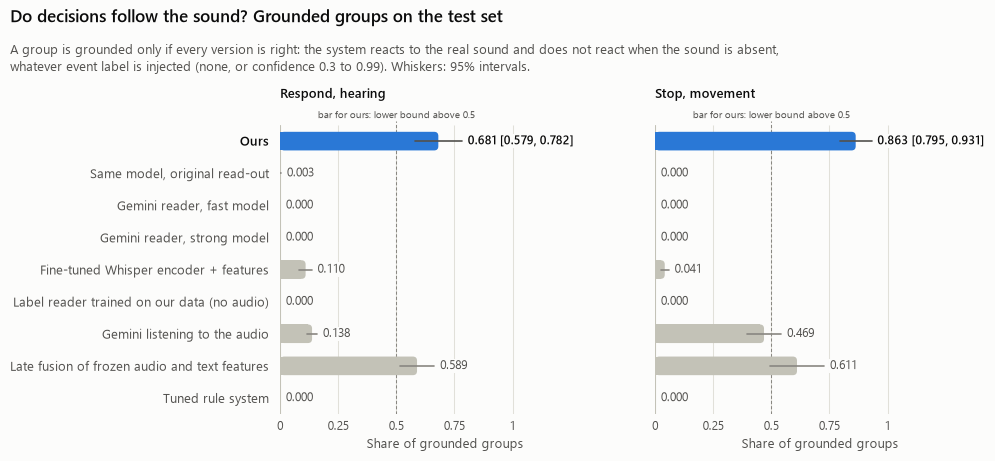

Respond, hearing: Ours 0.681; Same model, original read-out 0.003; Gemini reader, fast model 0.000; Gemini reader, strong model 0.000; Fine-tuned Whisper encoder + features 0.110; Label reader trained on our data (no audio) 0.000; Gemini listening to the audio 0.138; Late fusion of frozen audio and text features 0.589; Tuned rule system 0.000
Stop, movement: Ours 0.863; Same model, original read-out 0.000; Gemini reader, fast model 0.000; Gemini reader, strong model 0.000; Fine-tuned Whisper encoder + features 0.041; Label reader trained on our data (no audio) 0.000; Gemini listening to the audio 0.469; Late fusion of frozen audio and text features 0.611; Tuned rule system 0.000
Ours, Respond, hearing: 0.681 [0.579, 0.782]
Ours, Stop, movement: 0.863 [0.795, 0.931]


In [4]:
M1_KEY = {"ours": "2d", "L1": "old head"}   # the grounding report's keys for these two systems
crit = grounding["criteria"]["grounded"]
OURS_CRIT = {"r_hear": crit["G1a: main grounded group accuracy, lower bound > 0.5"],
             "s_move": crit["G1a-S: main grounded group accuracy, lower bound > 0.5"]}
rows_b = [k for k in ORDER if M1_KEY.get(k, k) in grounding["m1"]]


def grounded(k, part):
    """Grounded group accuracy of system k on one part: (point, lower, upper)."""
    if k == "ours":
        c = OURS_CRIT[part]
        assert abs(c["point"] - grounding["m1"]["2d"][part]["decision"]["right"]) < 1e-9
        return c["point"], c["ci95"][0], c["ci95"][1]
    m = grounding["m1"][M1_KEY.get(k, k)][part]
    lo, hi = m["grounded_ci"]["ci95"]
    return m["decision"]["right"], lo, hi


n = len(rows_b)
ys = np.arange(n)
plot_h, bottom = n * ROW + 0.35, 0.95
fig = plt.figure(figsize=(10.4, 1.2 + plot_h + bottom))
ylim = (n - 0.5, -1.0)
axes = []
for i, part in enumerate(("r_hear", "s_move")):
    ax = axes_in(fig, 2.95 + i * 3.75, bottom, 3.3, plot_h, sharey=axes[0] if axes else None)
    ax.set_xlim(0, 1.42)
    ax.set_ylim(*ylim)
    rows_axis(ax, ys, [0, 0.25, 0.5, 0.75, 1.0], ["0", "0.25", "0.5", "0.75", "1"])
    if i == 0:
        name_labels(ax, rows_b, ys)
    else:
        ax.tick_params(axis="y", labelleft=False)
    ax.plot([0.5, 0.5], [ylim[0], -0.62], color=MUTED, lw=0.75, ls=(0, (3, 2)), zorder=1)
    ax.text(0.5, -0.8, "bar for ours: lower bound above 0.5", ha="center", va="center", fontsize=7.5, color=INK2)
    for y, k in zip(ys, rows_b):
        v, lo, hi = grounded(k, part)
        hbar(ax, y, v, 0.58, OURS if k == "ours" else AXIS)
        if hi > lo:
            ax.plot([max(lo, 0), hi], [y, y], color=INK2 if k == "ours" else MUTED, lw=1.2, zorder=3)
        tip_label(ax, max(v, hi) + 0.025, y, f"{fixed(v)} [{fixed(lo)}, {fixed(hi)}]" if k == "ours" else fixed(v),
                  ours=k == "ours")
    ax.set_xlabel("Share of grounded groups")
    ax.set_title(PARTS[part])
    axes.append(ax)
heading(fig, "Do decisions follow the sound? Grounded groups on the test set",
        "A group is grounded only if every version is right: the system reacts to the real sound and does not "
        "react when the sound is absent,\nwhatever event label is injected (none, or confidence 0.3 to 0.99). "
        "Whiskers: 95% intervals.")
save(fig, "grounding_test.png")
plt.show()
for part in ("r_hear", "s_move"):
    print(PARTS[part] + ":", "; ".join(f"{NAMES[k]} {grounded(k, part)[0]:.3f}" for k in rows_b))
for part in ("r_hear", "s_move"):
    v, lo, hi = grounded("ours", part)
    print(f"Ours, {PARTS[part]}: {v:.3f} [{lo:.3f}, {hi:.3f}]")

## (c) Background noise on the test set

The two parts where only the sound decides were rendered again with 10 dB more background noise, and every
system ran at its frozen setting. The hollow dot is the clean accuracy, the filled dot the accuracy with the
extra noise; the column on the right gives the change in points. The text-only model is left out (it cannot
hear the events). The Gemini systems' clean questions were asked again together with the noisy ones, so their
clean values can differ slightly from figure (a).

saved docs/figures/noise_test.png


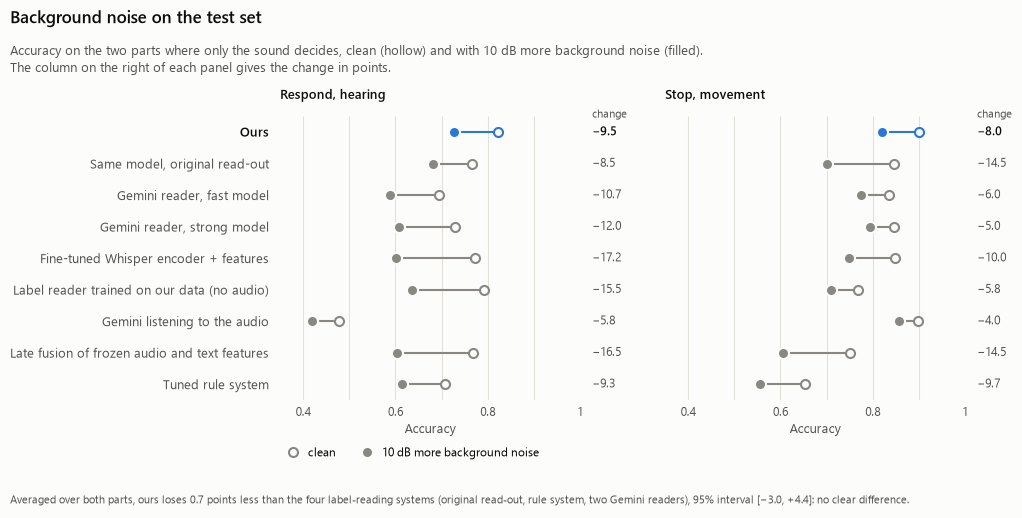

Respond, hearing:
  Ours                                             0.822 -> 0.727 (-9.5)
  Same model, original read-out                    0.767 -> 0.682 (-8.5)
  Gemini reader, fast model                        0.695 -> 0.588 (-10.7)
  Gemini reader, strong model                      0.728 -> 0.608 (-12.0)
  Fine-tuned Whisper encoder + features            0.773 -> 0.602 (-17.2)
  Label reader trained on our data (no audio)      0.792 -> 0.637 (-15.5)
  Gemini listening to the audio                    0.478 -> 0.420 (-5.8)
  Late fusion of frozen audio and text features    0.768 -> 0.603 (-16.5)
  Tuned rule system                                0.707 -> 0.613 (-9.3)
Stop, movement:
  Ours                                             0.900 -> 0.820 (-8.0)
  Same model, original read-out                    0.845 -> 0.700 (-14.5)
  Gemini reader, fast model                        0.835 -> 0.775 (-6.0)
  Gemini reader, strong model                      0.845 -> 0.795 (-5.0)
  Fine-tune

In [5]:
NOISE_KEY = {"ours": "2d"}
nz = noise["parts"]["dnoise10"]
rows_c = [k for k in ORDER if NOISE_KEY.get(k, k) in nz["r_hear"] and k != "T0"]
n = len(rows_c)
ys = np.arange(n)
plot_h, bottom = n * ROW + 0.2, 1.2
fig = plt.figure(figsize=(10.6, 1.2 + plot_h + bottom))
axes = []
for i, part in enumerate(("r_hear", "s_move")):
    ax = axes_in(fig, 2.95 + i * 3.85, bottom, 3.0, plot_h, sharey=axes[0] if axes else None)
    ax.set_xlim(0.35, 1.0)
    ax.set_ylim(n - 0.5, -0.7)
    rows_axis(ax, ys, [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], ["0.4", "", "0.6", "", "0.8", "", "1"], baseline=False)
    if i == 0:
        name_labels(ax, rows_c, ys)
    else:
        ax.tick_params(axis="y", labelleft=False)
    for y, k in zip(ys, rows_c):
        c = nz[part][NOISE_KEY.get(k, k)]
        col = OURS if k == "ours" else MUTED
        ax.plot([c["clean"], c["degraded"]], [y, y], color=col, lw=1.5, zorder=2)
        ax.plot(c["clean"], y, "o", ms=6.5, mfc=SURFACE, mec=col, mew=1.5, zorder=3)
        ax.plot(c["degraded"], y, "o", mfc=col, zorder=4, **DOT)
        ax.text(1.04, y, signed(100 * (c["degraded"] - c["clean"])), transform=ax.get_yaxis_transform(),
                va="center", fontsize=8.5, color=INK if k == "ours" else INK2,
                fontweight="semibold" if k == "ours" else "normal")
    ax.text(1.04, -0.55, "change", transform=ax.get_yaxis_transform(), va="center", fontsize=8, color=INK2)
    ax.set_xlabel("Accuracy")
    ax.set_title(PARTS[part])
    axes.append(ax)
handles = [Line2D([], [], ls="none", marker="o", ms=6.5, mfc=SURFACE, mec=MUTED, mew=1.5),
           Line2D([], [], ls="none", marker="o", mfc=MUTED, **DOT)]
fig.legend(handles, ["clean", "10 dB more background noise"], loc="lower left", ncol=2,
           bbox_to_anchor=(2.85 / fig.get_figwidth(), 0.5 / fig.get_figheight()), handletextpad=0.3,
           columnspacing=1.6)
g5 = noise["G5"]
gp, (glo, ghi) = 100 * g5["point"], (100 * g5["ci95"][0], 100 * g5["ci95"][1])
heading(fig, "Background noise on the test set",
        "Accuracy on the two parts where only the sound decides, clean (hollow) and with 10 dB more background "
        "noise (filled).\nThe column on the right of each panel gives the change in points.")
footnote(fig, f"Averaged over both parts, ours loses {abs(gp):.1f} points {'less' if gp >= 0 else 'more'} than the "
              "four label-reading systems (original read-out, rule system, two Gemini readers), 95% interval "
              f"[{signed(glo)}, {signed(ghi)}]: no clear difference.")
save(fig, "noise_test.png")
plt.show()
for part in ("r_hear", "s_move"):
    print(PARTS[part] + ":")
    for k in rows_c:
        c = nz[part][NOISE_KEY.get(k, k)]
        print(f"  {NAMES[k]:48s} {c['clean']:.3f} -> {c['degraded']:.3f} ({100 * (c['degraded'] - c['clean']):+.1f})")
print(f"Label readers' loss minus ours' loss: {gp:+.1f} [{glo:+.1f}, {ghi:+.1f}] points")

## (d) When noise masks the sound (replication split)

This check ran once on a second held-out split, the replication split. The background noise of the two
sound-only parts was raised by 10 to 40 dB while the transcripts stayed clean. Each point is one of the four
background recordings (kitchen, field, river, restaurant) at one noise level. The x-axis is the damage to our
model's hearing: the accuracy it loses, relative to the clean version, when it is given no detector labels.
The y-axis is ours minus the original read-out when both are given true labels. The original read-out follows
the labels, so true labels keep it accurate whatever the noise; ours relies on its own hearing and falls
behind as the hearing is damaged. The line is a least-squares fit over the noisy points, computed here.
Below the figure, the same slopes are printed from `mirror_vs_ears_newnoise.json` for two wider sets: the
replication cells pooled with three noise types of the development split, and four appliance noise types
from a second noise corpus mixed into the replication scenes (a check that was not confirmatory).

saved

 docs/figures/masked_sound_replication.png


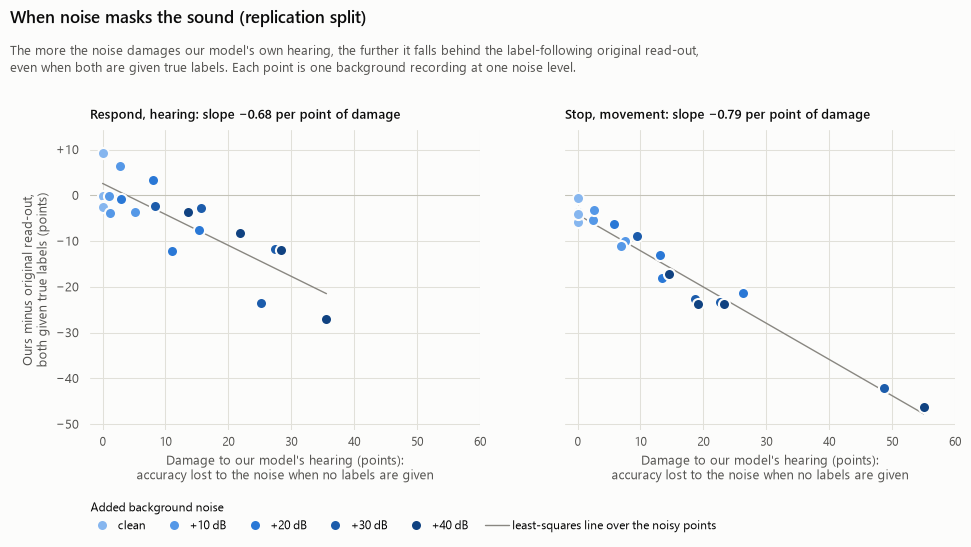

Replication split, Respond, hearing: slope -0.68, intercept +2.6 points, over 16 noisy cells
Replication split, Stop, movement: slope -0.79, intercept -4.2 points, over 16 noisy cells
development + replication noise types, Respond, hearing: slope -0.90 over 28 noisy cells
development + replication noise types, Stop, movement: slope -0.81 over 28 noisy cells
four appliance noise types, second corpus, Respond, hearing: slope -0.92 over 16 noisy cells
four appliance noise types, second corpus, Stop, movement: slope -0.88 over 16 noisy cells


In [6]:
LEVEL = {"dclean": "clean", "dnoise10": "+10 dB", "dnoise20": "+20 dB", "dnoise30": "+30 dB", "dnoise40": "+40 dB"}
cells = list(mirror["cells"].values())
assert mirror["split"] == "replication" and {c["level"] for c in cells} == set(LEVEL)


def slope_intercept(x, y):
    x, y = np.asarray(x), np.asarray(y)
    b = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
    return b, y.mean() - b * x.mean()


fig = plt.figure(figsize=(10.2, 5.65))
xmax = 100 * max(c["ear_damage"] for c in cells) + 5
ylo = 100 * min(c["mirror"] for c in cells) - 5
yhi = 100 * max(c["mirror"] for c in cells) + 5
fits, axes = {}, []
for i, part in enumerate(("r_hear", "s_move")):
    ax = axes_in(fig, 1.05 + i * 4.75, 1.25, 3.9, 3.0, sharey=axes[0] if axes else None)
    ax.set_xlim(-2, xmax)
    ax.set_ylim(ylo, yhi)
    ax.grid(True, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.axhline(0, color=AXIS, lw=0.75, zorder=1)
    ax.yaxis.set_major_formatter(lambda v, _: signed(v, 0) if v else "0")
    if i:
        ax.tick_params(axis="y", labelleft=False)
    noisy = [c for c in cells if c["side"] == part and c["level"] != "dclean"]
    b, a = slope_intercept([100 * c["ear_damage"] for c in noisy], [100 * c["mirror"] for c in noisy])
    fits[part] = (b, a, len(noisy))
    xx = np.array([0, max(100 * c["ear_damage"] for c in noisy)])
    ax.plot(xx, a + b * xx, color=MUTED, lw=1.0, zorder=2)
    for lv, col in zip(LEVEL, LEVELS):
        cs = [c for c in cells if c["side"] == part and c["level"] == lv]
        ax.plot([100 * c["ear_damage"] for c in cs], [100 * c["mirror"] for c in cs], "o", ls="none", mfc=col,
                zorder=3 + list(LEVEL).index(lv), **DOT)
    ax.set_title(f"{PARTS[part]}: slope {signed(b, 2)} per point of damage")
    ax.set_xlabel("Damage to our model's hearing (points):\naccuracy lost to the noise when no labels are given")
    if i == 0:
        ax.set_ylabel("Ours minus original read-out,\nboth given true labels (points)")
    axes.append(ax)
handles = [Line2D([], [], ls="none", marker="o", mfc=c, **DOT) for c in LEVELS]
handles.append(Line2D([], [], color=MUTED, lw=1.0))
fig.legend(handles, list(LEVEL.values()) + ["least-squares line over the noisy points"], loc="lower left",
           ncol=6, bbox_to_anchor=(0.95 / fig.get_figwidth(), 0.12 / fig.get_figheight()),
           title="Added background noise", title_fontsize=8.5, alignment="left", handletextpad=0.3,
           columnspacing=1.4)
heading(fig, "When noise masks the sound (replication split)",
        "The more the noise damages our model's own hearing, the further it falls behind the label-following "
        "original read-out,\neven when both are given true labels. Each point is one background recording at one "
        "noise level.")
save(fig, "masked_sound_replication.png")
plt.show()
for part, (b, a, k) in fits.items():
    print(f"Replication split, {PARTS[part]}: slope {b:+.2f}, intercept {a:+.1f} points, over {k} noisy cells")
wider = load("mirror_vs_ears_newnoise.json")
for key, what in (("summary_demand", "development + replication noise types"),
                  ("summary_new_types", "four appliance noise types, second corpus")):
    for part in ("r_hear", "s_move"):
        s = wider[key][part]
        print(f"{what}, {PARTS[part]}: slope {s['slope']:+.2f} over {s['n_cells']} noisy cells")

## (e) Read-out iterations on the development set

Each version changes only the read-out on top of the same fine-tuned model:

| Version | What changed |
|---|---|
| Original read-out | LoRA fine-tune on natural labels |
| Step 2 | Read-out retrained on last-layer states plus a summary of the audio encoder; event labels made independent of the sound |
| Step 2b | All detector classes made independent of the sound |
| Step 2c | False labels copied from the timing of real labels |
| Step 2d (final) | Read-out sees the audio encoder second by second |

The values come from `grounding_v06_dev.json` (`natural.candidates`): the natural five-part mean and the
grounded group accuracy on the two sound-only parts. The development set has few door recordings, so the
intervals for "stop, movement" are wide (step 2d: 0.81 [0.51, 1.10], a t-interval with 4 degrees of
freedom); they are left out of the figure.

saved docs/figures/readout_iterations_dev.png


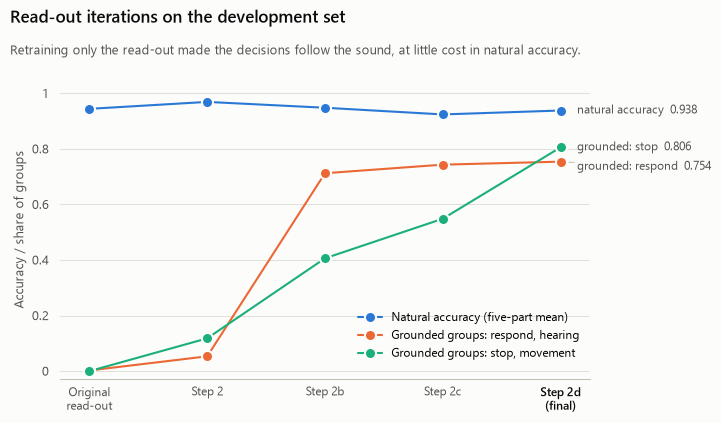

Original read-out  natural 0.944  respond grounded 0.003  stop grounded 0.000
Step 2             natural 0.969  respond grounded 0.053  stop grounded 0.118
Step 2b            natural 0.948  respond grounded 0.713  stop grounded 0.406
Step 2c            natural 0.924  respond grounded 0.743  stop grounded 0.549
Step 2d (final)    natural 0.938  respond grounded 0.754  stop grounded 0.806


In [7]:
VERSIONS = [("old head", "Original\nread-out"), ("step 2 ears", "Step 2"), ("2b ears", "Step 2b"),
            ("2c ears", "Step 2c"), ("2d", "Step 2d\n(final)")]
cand = grounding_dev["natural"]["candidates"]
series = [("Natural accuracy (five-part mean)", "natural accuracy", [cand[v]["five_part"] for v, _ in VERSIONS]),
          ("Grounded groups: respond, hearing", "grounded: respond",
           [cand[v]["grounded"]["r_hear"]["point"] for v, _ in VERSIONS]),
          ("Grounded groups: stop, movement", "grounded: stop",
           [cand[v]["grounded"]["s_move"]["point"] for v, _ in VERSIONS])]

fig = plt.figure(figsize=(8.4, 4.75))
ax = axes_in(fig, 0.75, 0.85, 5.3, 3.0)
xs = np.arange(len(VERSIONS))
ax.set_xlim(-0.25, len(VERSIONS) - 0.75)
ax.set_ylim(-0.03, 1.05)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0], ["0", "0.2", "0.4", "0.6", "0.8", "1"])
ax.yaxis.grid(True, zorder=0)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.set_xticks(xs, [lab for _, lab in VERSIONS])
ax.get_xticklabels()[-1].set_fontweight("semibold")
ax.get_xticklabels()[-1].set_color(INK)
ends = []
for (_, short, vals), col in zip(series, SERIES):
    ax.plot(xs, vals, color=col, lw=1.5, zorder=3)
    ax.plot(xs, vals, "o", ls="none", mfc=col, zorder=4, **DOT)
    ends.append([vals[-1], short, vals[-1]])
ends.sort(key=lambda e: -e[0])
for j in range(1, len(ends)):          # keep the end labels at least 0.07 apart
    ends[j][0] = min(ends[j][0], ends[j - 1][0] - 0.07)
for ypos, short, v in ends:
    ax.annotate(f"{short}  {fixed(v)}", (xs[-1], v), xytext=(xs[-1] + 0.14, ypos), textcoords="data",
                va="center", fontsize=8.5, color=INK2, annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.75, shrinkA=0, shrinkB=6)
                if abs(ypos - v) > 0.005 else None)
ax.legend([Line2D([], [], color=c, lw=1.5, marker="o", mfc=c, **DOT) for c in SERIES], [s[0] for s in series],
          loc="lower right", bbox_to_anchor=(1.0, 0.03))
ax.set_ylabel("Accuracy / share of groups")
heading(fig, "Read-out iterations on the development set",
        "Retraining only the read-out made the decisions follow the sound, at little cost in natural accuracy.")
save(fig, "readout_iterations_dev.png")
plt.show()
for v, lab in VERSIONS:
    c = cand[v]
    print(f"{lab.replace(chr(10), ' '):18s} natural {c['five_part']:.3f}  respond grounded "
          f"{c['grounded']['r_hear']['point']:.3f}  stop grounded {c['grounded']['s_move']['point']:.3f}")

## (f) Where the errors are: front-end state on the test set

Natural "respond, hearing" points where the Whisper transcript and the speaker tag are both right, split by
what the sound-event detector reported in the 8-second window: no real event and no label of confidence 0.5
or more (clean window), such a label without a real event (false label), a real event without such a label
(missed event), or a real event with such a label (right label). Each bar is the share of wrong respond decisions. The
false-label and missed-event groups are small (21 and 24 points). The reference reader is given perfect
labels, so its bars show what is left when the labels are right.

saved docs/figures/errors_by_front_end_test.png


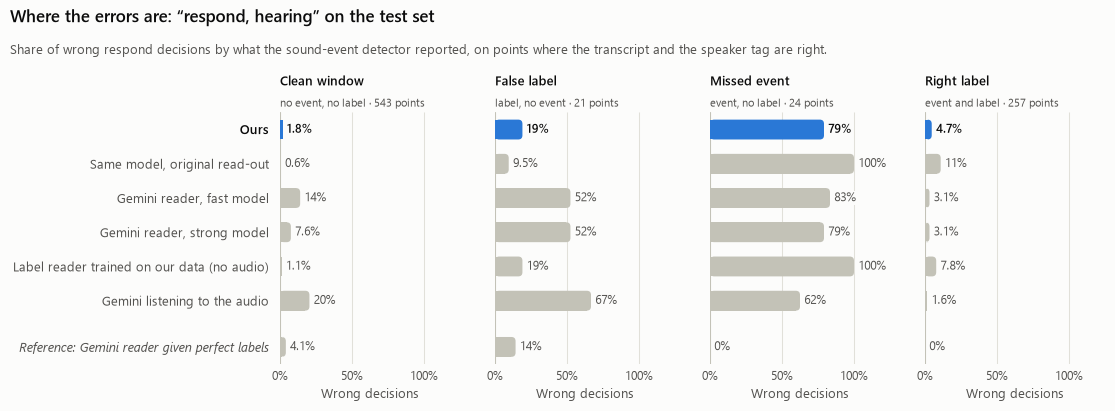

Clean window (543 points): Ours 1.8%; Same model, original read-out 0.6%; Gemini reader, fast model 14.0%; Gemini reader, strong model 7.6%; Label reader trained on our data (no audio) 1.1%; Gemini listening to the audio 20.4%; Reference: Gemini reader given perfect labels 4.1%
False label (21 points): Ours 19.0%; Same model, original read-out 9.5%; Gemini reader, fast model 52.4%; Gemini reader, strong model 52.4%; Label reader trained on our data (no audio) 19.0%; Gemini listening to the audio 66.7%; Reference: Gemini reader given perfect labels 14.3%
Missed event (24 points): Ours 79.2%; Same model, original read-out 100.0%; Gemini reader, fast model 83.3%; Gemini reader, strong model 79.2%; Label reader trained on our data (no audio) 100.0%; Gemini listening to the audio 62.5%; Reference: Gemini reader given perfect labels 0.0%
Right label (257 points): Ours 4.7%; Same model, original read-out 10.9%; Gemini reader, fast model 3.1%; Gemini reader, strong model 3.1%; Label reader tra

In [8]:
STATES = [("clean", "Clean window", "no event, no label"), ("false label", "False label", "label, no event"),
          ("missed event", "Missed event", "event, no label"), ("right label", "Right label", "event and label")]
ebf = grounding["natural"]["errors_by_front_end_part"]
cell = {s: ebf[f"transcript ok | tag ok | {s}"] for s, _, _ in STATES}
rows_f = [k for k in ORDER if k in cell["clean"]] + [REFERENCE]
n = len(rows_f)
ys = np.arange(n, dtype=float)
ys[-1] += 0.35                       # set the reference row apart
plot_h, bottom = n * ROW + 0.45, 0.8
fig = plt.figure(figsize=(11.6, 1.2 + plot_h + bottom))
axes = []
for i, (s, title, sub) in enumerate(STATES):
    ax = axes_in(fig, 2.95 + i * 2.15, bottom, 1.8, plot_h, sharey=axes[0] if axes else None)
    ax.set_xlim(0, 125)
    ax.set_ylim(ys[-1] + 0.5, -0.6)
    rows_axis(ax, ys, [0, 50, 100], ["0%", "50%", "100%"])
    if i == 0:
        name_labels(ax, rows_f, ys)
    else:
        ax.tick_params(axis="y", labelleft=False)
    for y, k in zip(ys, rows_f):
        v = 100 * cell[s][k]
        hbar(ax, y, v, 0.58, OURS if k == "ours" else AXIS)
        tip_label(ax, v + 3, y, f"{v:.1f}%" if 0 < v < 10 else f"{v:.0f}%", ours=k == "ours")
    ax.set_title(title, pad=17)
    ax.text(0, 1.0, f"{sub} · {cell[s]['n']} points", transform=ax.transAxes, fontsize=8, color=INK2,
            va="bottom", ha="left")
    ax.set_xlabel("Wrong decisions")
    axes.append(ax)
heading(fig, "Where the errors are: “respond, hearing” on the test set",
        "Share of wrong respond decisions by what the sound-event detector reported, on points where the "
        "transcript and the speaker tag are right.")
save(fig, "errors_by_front_end_test.png")
plt.show()
for s, title, _ in STATES:
    print(f"{title} ({cell[s]['n']} points): " + "; ".join(f"{NAMES[k]} {100 * cell[s][k]:.1f}%" for k in rows_f))

## Key numbers

The headline values quoted in the README, read from the same files.

In [9]:
print("Test set, five-part mean:")
for k in ("ours", "L1", "B2-fast", "B2-strong", "B3", "B1-strong"):
    print(f"  {NAMES[k]:32s} {S[k]['primary']:.3f}")
for k in ("B2-fast", "B2-strong", "B3", "B1-strong", "B2-local"):
    p, lo, hi = ours_minus(k)
    print(f"  Ours minus {NAMES[k]:38s} {p:+.1f} [{lo:+.1f}, {hi:+.1f}] points")
for part in ("r_hear", "s_move"):
    v, lo, hi = grounded("ours", part)
    print(f"Ours, grounded groups, {PARTS[part]:17s} {v:.3f} [{lo:.3f}, {hi:.3f}]")
print("Figures:", ", ".join(sorted(p.name for p in FIG.glob("*.png"))))

Test set, five-part mean:
  Ours                             0.910
  Same model, original read-out    0.861
  Gemini reader, fast model        0.854
  Gemini reader, strong model      0.851
  Gemini listening to the audio    0.766
  Tuned rule system                0.597
  Ours minus Gemini reader, fast model              +5.6 [+2.8, +8.3] points
  Ours minus Gemini reader, strong model            +5.3 [+1.8, +8.9] points
  Ours minus Gemini listening to the audio          +12.4 [+8.9, +15.8] points
  Ours minus Tuned rule system                      +31.3 [+26.5, +36.1] points
  Ours minus Local LLM reader (Qwen3.5-4B, 4-bit)   +78.4 [+75.3, +81.5] points
Ours, grounded groups, Respond, hearing  0.681 [0.579, 0.782]
Ours, grounded groups, Stop, movement    0.863 [0.795, 0.931]
Figures: errors_by_front_end_test.png, grounding_test.png, main_comparison_test.png, masked_sound_replication.png, noise_test.png, readout_iterations_dev.png
